In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.style
from collections import Counter
# from IPython.display import Image

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

import folium
from folium.plugins import MarkerCluster

from tabulate import tabulate
from warnings import filterwarnings
filterwarnings("ignore", category=DeprecationWarning)

In [ ]:
from pathlib import Path

def locate_listings():
    """Find data/Airbnb_Data.csv from the repo root, regardless of where the kernel was started."""
    start = Path.cwd().resolve()
    for base in [start, *start.parents]:
        candidate = base / "data" / "Airbnb_Data.csv"
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(
        "Could not find data/Airbnb_Data.csv. "
        "Keep the CSV in the data folder at the repository root."
    )

DATA_CSV = locate_listings()
print("Listings file:", DATA_CSV)


In [15]:
#Loading the data set
df1=pd.read_csv(DATA_CSV, low_memory=False)
df1.head()

C:\Users\BHAVIN JOSHI\AppData\Local\Temp\ipykernel_12152\2953522889.py:2: DtypeWarning: Columns (25) have mixed types. Specify dtype option on import or set low_memory=False.
  df1=pd.read_csv("Airbnb_Data.csv")


,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,country,...,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365,house_rules,license
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,United States,...,$193,10.0,9.0,10/19/2021,0.21,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,NaN
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,United States,...,$28,30.0,45.0,5/21/2022,0.38,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,NaN
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,NaN,Elise,Manhattan,Harlem,40.80902,-73.94190,United States,...,$124,3.0,0.0,NaN,NaN,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",NaN
3,1002755,NaN,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,40.68514,-73.95976,United States,...,$74,30.0,270.0,7/5/2019,4.64,4.0,1.0,322.0,NaN,NaN
4,1003689,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,40.79851,-73.94399,United States,...,$41,10.0,9.0,11/19/2018,0.10,3.0,1.0,289.0,"Please no smoking in the house, porch or on th...",NaN


**Exploratory Data Analysis**

**Data Pre-Processing**

In [16]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102599 entries, 0 to 102598
Data columns (total 26 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   id                              102599 non-null  int64  
 1   NAME                            102349 non-null  object 
 2   host id                         102599 non-null  int64  
 3   host_identity_verified          102310 non-null  object 
 4   host name                       102193 non-null  object 
 5   neighbourhood group             102570 non-null  object 
 6   neighbourhood                   102583 non-null  object 
 7   lat                             102591 non-null  float64
 8   long                            102591 non-null  float64
 9   country                         102067 non-null  object 
 10  country code                    102468 non-null  object 
 11  instant_bookable                102494 non-null  object 
 12  cancellation_pol

In [17]:
df1.isnull().sum()

id                                     0
NAME                                 250
host id                                0
host_identity_verified               289
host name                            406
neighbourhood group                   29
neighbourhood                         16
lat                                    8
long                                   8
country                              532
country code                         131
instant_bookable                     105
cancellation_policy                   76
room type                              0
Construction year                    214
price                                247
service fee                          273
minimum nights                       409
number of reviews                    183
last review                        15893
reviews per month                  15879
review rate number                   326
calculated host listings count       319
availability 365                     448
house_rules     

In [18]:
# Fill missing values in the second column ('NAME') with "No Name"
df1.iloc[:,1].fillna("No Name", inplace=True)

# Fill missing values in the fourth column ('host_identity_verified') with "Host identity not verified"
df1.iloc[:,3].fillna("Host identity not verified", inplace=True)

# Fill missing values in the fifth column ('host name') with "No Host Name"
df1.iloc[:,4].fillna("No Host Name", inplace=True)

# Fill missing values in the second-to-last column ('house_rules') with "Not Mentioned"
df1.iloc[:,-2].fillna("Not Mentioned", inplace=True)

# Drop rows with missing values in the 'lat' and 'long' columns
df1.dropna(subset=['lat','long'], inplace=True)


C:\Users\BHAVIN JOSHI\AppData\Local\Temp\ipykernel_12152\1824859061.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df1.iloc[:,1].fillna("No Name", inplace=True)
C:\Users\BHAVIN JOSHI\AppData\Local\Temp\ipykernel_12152\1824859061.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a cop

In [19]:
df1.isnull().sum()

id                                     0
NAME                                   0
host id                                0
host_identity_verified                 0
host name                              0
neighbourhood group                   29
neighbourhood                         16
lat                                    0
long                                   0
country                              532
country code                         131
instant_bookable                     105
cancellation_policy                   76
room type                              0
Construction year                    213
price                                247
service fee                          273
minimum nights                       409
number of reviews                    183
last review                        15892
reviews per month                  15878
review rate number                   326
calculated host listings count       319
availability 365                     448
house_rules     

In [20]:
#Printing rows with missing values in neighbourhood group

#We are printitng the rows with missing values in neighbourhood group to see that latitude and longitude are not missing
null_rows = df1.loc[df1['neighbourhood group'].isnull()]

print(null_rows)
print(null_rows.index)
index1=null_rows.index
print(index1)


             id                                               NAME  \
74      1042206                    HARLEM, NEW YORK WELCOMES YOU!!   
75      1042759                              BLUE TRIM GUEST HOUSE   
76      1043311             Charming East Village One Bedroom Flat   
77      1043863                                     Manhattan Room   
78      1044415                              Little King of Queens   
90      1051043                  Cozy Bedroom in Williamsburg 3 BR   
91      1051595                Sunny room+Pvte office in huge loft   
92      1052148                Spacious Prospect Heights Apartment   
148     1083076                                            NYC Zen   
161     1090256                   Indie-Chic Share In Williamsburg   
168     1094122                 Parlor Room In Victorian Townhouse   
196     1109587                        Prime Location in Manhattan   
206     1115110                                            No Name   
241     1134440     

In [21]:

# import module
from geopy.geocoders import Nominatim

# initialize Nominatim API 
geolocator = Nominatim(user_agent="geoapiExercises")


In [22]:
# Import the Nominatim class from the geopy.geocoders module
from geopy.geocoders import Nominatim

# Initialize the geolocator object with a user-defined user_agent
geolocator = Nominatim(user_agent="my_geocoder")

# Loop through each index value in the 'index1' list or array
for i in index1:
    # Retrieve latitude and longitude values for the current row 'i' from the DataFrame 'df1'
    Latitude_plus = df1.loc[i, 'lat']  
    Longitude_plus = df1.loc[i, 'long']  
    
    # Convert latitude and longitude values to string format
    Latitude = str(Latitude_plus)
    Longitude = str(Longitude_plus)
    
    # Use the geolocator object to reverse-geocode the latitude and longitude values
    location = geolocator.reverse(Latitude + "," + Longitude)
    
    # Extract the address information from the reverse-geocoded location
    address = location.raw['address']
    
    # Extract the suburb or neighborhood group information from the address
    # and assign it to the 'neighbourhood group' column in the DataFrame 'df1'
    neighbourhood_group_find = address.get('suburb', '')
    df1.loc[i,"neighbourhood group"] = neighbourhood_group_find

In [23]:
#Printing rows with missing values in neighbourhood

#We are printitng the rows with missing values in neighbourhood to see that latitude and longitude are not missing
null_rows_nbh = df1.loc[df1['neighbourhood'].isnull()]

print(null_rows_nbh)
print(null_rows_nbh.index)
index2=null_rows_nbh.index
print(index1)


          id                                            NAME      host id  \
517  1286875             "The Oasis" on Bedford Williamsburg  30603782652   
547  1303444                       STYLISH EAST VILLAGE FLAT   6825076306   
553  1306758            Comfortable. Spacious. Private Room.  45534966158   
575  1318909    2 Bed, 2 Bath Apartment on Central Park West  86633710982   
589  1326641                           CBG Helps Haiti Rm #3  33952991254   
613  1339896               Wonderfully inviting East Village  84560895335   
624  1345971           Stylish Studio with exclusive Terrace  21547822804   
633  1350942             Lower East Side/Chinatown 1 Bedroom  58408401042   
643  1356465                        2BR  Apt - 20min to Soho  21192497123   
670  1371377                Loft Suite @ The Box House Hotel  75427375884   
678  1375795                Loft Suite @ The Box House Hotel  34416621424   
681  1377452               Loft w/ Terrace @ Box House Hotel  77372797211   

In [ ]:
# Import the Nominatim class from the geopy.geocoders module
from geopy.geocoders import Nominatim

# Initialize the geolocator object with a user-defined user_agent
geolocator = Nominatim(user_agent="my_geocoder")

# Loop through each index value in the 'index2' list or array
for i in index2:
    # Check if the 'neighbourhood' column is null for the current row 'i'
    if pd.isnull(df1.loc[i, 'neighbourhood']):
        # Retrieve latitude and longitude values for the current row 'i' from the DataFrame 'df1'
        Latitude_plus = df1.loc[i, 'lat']
        Longitude_plus = df1.loc[i, 'long']
        
        # Convert latitude and longitude values to string format
        Latitude = str(Latitude_plus)
        Longitude = str(Longitude_plus)
        
        # Use the geolocator object to reverse-geocode the latitude and longitude values
        location = geolocator.reverse(Latitude + "," + Longitude)
        
        # Extract the address information from the reverse-geocoded location
        address = location.raw['address']
        
        # Extract the neighbourhood information from the address
        neighbourhood_find = address.get('neighbourhood', '')
        
        # Update the 'neighbourhood' column in the DataFrame 'df1' with the found neighbourhood
        df1.loc[i, "neighbourhood"] = neighbourhood_find

# Check for missing values in the DataFrame 'df1' after updating 'neighbourhood' column
df1.isnull().sum()


In [ ]:
# Convert 'price' column to string data type
df1['price'] = df1['price'].astype(str)

# Convert 'service fee' column to string data type
df1['service fee'] = df1['service fee'].astype(str)

# Remove $ sign from 'price' column
df1['price'] = df1['price'].str.replace('$', '')

# Remove $ sign from 'service fee' column
df1['service fee'] = df1['service fee'].str.replace('$', '')

print(df1['price'])
print(df1['service fee'])

0           966 
1           142 
2           620 
3           368 
4           204 
           ...  
102594      844 
102595      837 
102596      988 
102597      546 
102598    1,032 
Name: price, Length: 102591, dtype: object
0         193 
1          28 
2         124 
3          74 
4          41 
          ... 
102594    169 
102595    167 
102596    198 
102597    109 
102598    206 
Name: service fee, Length: 102591, dtype: object


In [ ]:
df1.isnull().sum()

id                                     0
NAME                                   0
host id                                0
host_identity_verified                 0
host name                              0
neighbourhood group                    0
neighbourhood                          0
lat                                    0
long                                   0
country                              532
country code                         131
instant_bookable                     105
cancellation_policy                   76
room type                              0
Construction year                    213
price                                  0
service fee                            0
minimum nights                       409
number of reviews                    183
last review                        15892
reviews per month                  15878
review rate number                   326
calculated host listings count       319
availability 365                     448
house_rules     

In [ ]:
# Remove commas and whitespace from 'price' column
df1['price'] = df1['price'].str.replace(',', '').str.strip()

# Remove commas and whitespace from 'service fee' column
df1['service fee'] = df1['service fee'].str.replace(',', '').str.strip()

# Convert 'price' column to float data type
df1['price'] = df1['price'].astype(float)

# Convert 'service fee' column to float data type
df1['service fee'] = df1['service fee'].astype(float)

# Calculate the mean of non-null values in 'price' column
price_mean = df1['price'].mean()

# Fill null values in 'price' column with the calculated mean
df1['price'].fillna(price_mean, inplace=True)

# Calculate the mean of non-null values in 'service fee' column
service_fee_mean = df1['service fee'].mean()

# Fill null values in 'service fee' column with the calculated mean
df1['service fee'].fillna(service_fee_mean, inplace=True)

# Convert 'reviews per month' column to float data type
df1['reviews per month'] = df1['reviews per month'].astype(float)

# Display DataFrame to verify changes
df1.isnull().sum()


C:\Users\BHAVIN JOSHI\AppData\Local\Temp\ipykernel_13532\1332040338.py:17: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df1['price'].fillna(price_mean, inplace=True)
C:\Users\BHAVIN JOSHI\AppData\Local\Temp\ipykernel_13532\1332040338.py:23: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a c

id                                     0
NAME                                   0
host id                                0
host_identity_verified                 0
host name                              0
neighbourhood group                    0
neighbourhood                          0
lat                                    0
long                                   0
country                              532
country code                         131
instant_bookable                     105
cancellation_policy                   76
room type                              0
Construction year                    213
price                                  0
service fee                            0
minimum nights                       409
number of reviews                    183
last review                        15892
reviews per month                  15878
review rate number                   326
calculated host listings count       319
availability 365                     448
house_rules     

In [ ]:
# Fill missing values in the 'country' column with 'United States'
df1['country'].fillna('United States', inplace=True)

# Fill missing values in the 'country code' column with 'US'
df1['country code'].fillna('US', inplace=True)

# Fill missing values in the 'instant_bookable' column with 'FALSE'
df1['instant_bookable'].fillna('FALSE', inplace=True)

# Fill missing values in the 'cancellation_policy' column with the mode (most frequent value)
# Mode is calculated using the mode() function, and [0] retrieves the first mode if there are multiple modes
df1['cancellation_policy'] = df1['cancellation_policy'].fillna(df1['cancellation_policy'].mode()[0])

# Fill missing values in the 'Construction year' column with the mode (most frequent value)
# Mode is calculated using the mode() function, and [0] retrieves the first mode if there are multiple modes
df1['Construction year'].fillna(df1['Construction year'].mode()[0], inplace=True)


C:\Users\BHAVIN JOSHI\AppData\Local\Temp\ipykernel_13532\2844568770.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df1['country'].fillna('United States', inplace=True)
C:\Users\BHAVIN JOSHI\AppData\Local\Temp\ipykernel_13532\2844568770.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves a

In [ ]:
# Fill missing values in the 'minimum nights' column with the mode (most frequent value)
# Mode is calculated using the mode() function, and [0] retrieves the first mode if there are multiple modes
df1['minimum nights'].fillna(df1['minimum nights'].mode()[0], inplace=True)

# Fill missing values in the 'number of reviews' column with the mode (most frequent value)
# Mode is calculated using the mode() function, and [0] retrieves the first mode if there are multiple modes
df1['number of reviews'].fillna(df1['number of reviews'].mode()[0], inplace=True)

# Fill missing values in the 'last review' column with 'No Date'
df1['last review'].fillna('No Date', inplace=True)

# Fill missing values in the 'reviews per month' column with 0.0
df1['reviews per month'].fillna(0.0, inplace=True)

# Fill missing values in the 'review rate number' column with 'no review rate number'
df1['review rate number'].fillna('no review rate number', inplace=True)

# Fill missing values in the 'calculated host listings count' column with 1
df1['calculated host listings count'].fillna(1, inplace=True)

# Fill missing values in the 'availability 365' column with 1
df1['availability 365'].fillna(1, inplace=True)

# Fill missing values in the 'license' column with 'no license'
df1['license'].fillna('no license', inplace=True)


C:\Users\BHAVIN JOSHI\AppData\Local\Temp\ipykernel_13532\320810926.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df1['minimum nights'].fillna(df1['minimum nights'].mode()[0], inplace=True)
C:\Users\BHAVIN JOSHI\AppData\Local\Temp\ipykernel_13532\320810926.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting va

In [ ]:
df1.isnull().sum()

id                                0
NAME                              0
host id                           0
host_identity_verified            0
host name                         0
neighbourhood group               0
neighbourhood                     0
lat                               0
long                              0
country                           0
country code                      0
instant_bookable                  0
cancellation_policy               0
room type                         0
Construction year                 0
price                             0
service fee                       0
minimum nights                    0
number of reviews                 0
last review                       0
reviews per month                 0
review rate number                0
calculated host listings count    0
availability 365                  0
house_rules                       0
license                           0
dtype: int64

**Data Visualization**

array([[<Axes: title={'center': 'id'}>,
        <Axes: title={'center': 'host id'}>,
        <Axes: title={'center': 'lat'}>],
       [<Axes: title={'center': 'long'}>,
        <Axes: title={'center': 'Construction year'}>,
        <Axes: title={'center': 'price'}>],
       [<Axes: title={'center': 'service fee'}>,
        <Axes: title={'center': 'minimum nights'}>,
        <Axes: title={'center': 'number of reviews'}>],
       [<Axes: title={'center': 'reviews per month'}>,
        <Axes: title={'center': 'calculated host listings count'}>,
        <Axes: title={'center': 'availability 365'}>]], dtype=object)

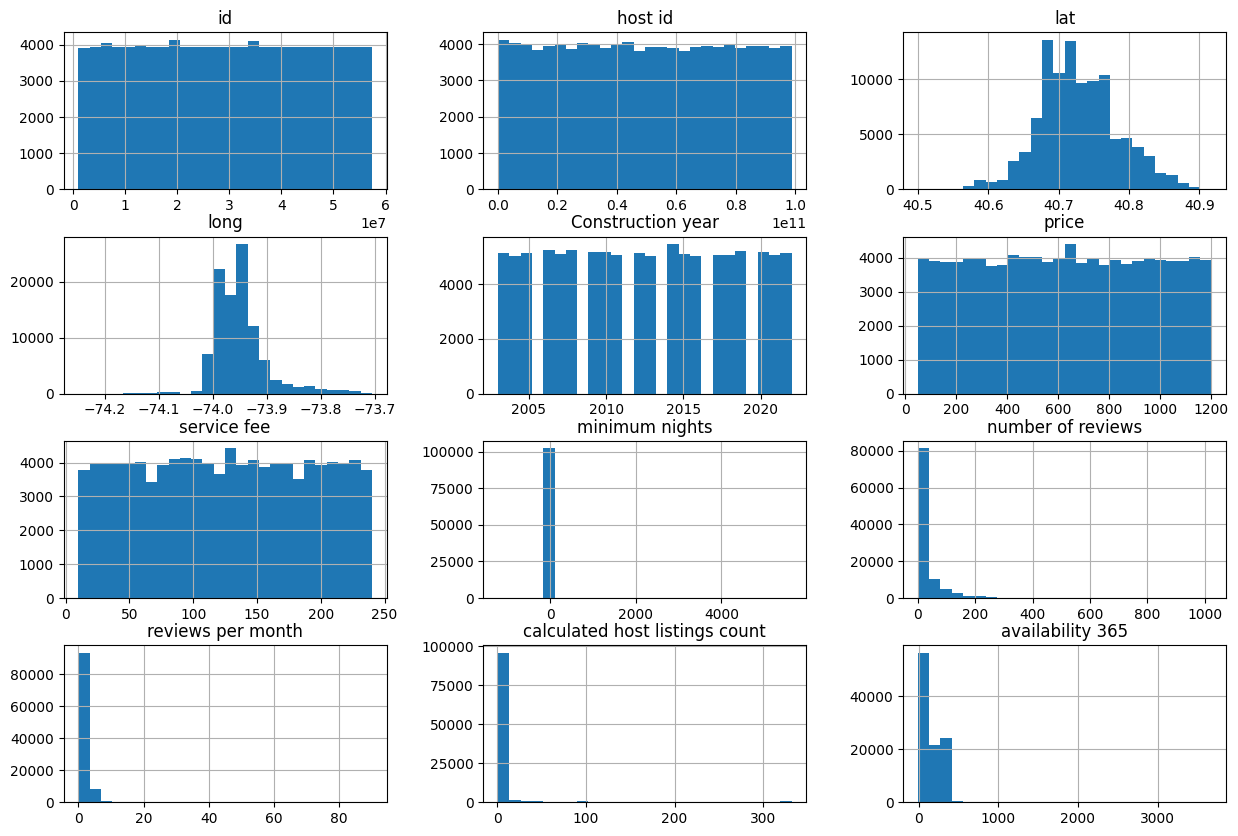

In [ ]:
df1.hist(bins=26, figsize=(15,10))

In [ ]:
# Display summary statistics for selected columns
df1[['price', 'availability 365', 'service fee', 'reviews per month', 'number of reviews']].describe()

,price,availability 365,service fee,reviews per month,number of reviews
count,102591.000000,102591.000000,102591.000000,102591.000000,102591.000000
mean,625.300711,140.519968,125.028343,1.161426,27.434102
std,331.277912,135.457291,66.238593,1.680970,49.478291
min,50.000000,-10.000000,10.000000,0.000000,0.000000
25%,341.000000,2.000000,68.000000,0.090000,1.000000
50%,625.300711,95.000000,125.000000,0.480000,7.000000
75%,912.000000,268.000000,182.000000,1.710000,30.000000
max,1200.000000,3677.000000,240.000000,90.000000,1024.000000


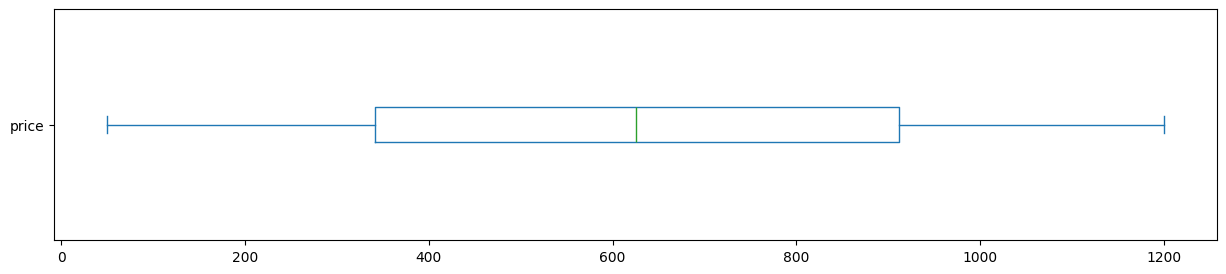

Values over $500.00: 
62579
60.9985%


Values equal to $0: 
0
0.0000%


In [ ]:
# Displaying the box plot
df1['price'].plot(kind='box', vert=False, figsize=(15,3))
plt.show()

# Calculating the number and the percentage of prices that are equal to $0 and over $500.00
print('Values over $500.00: ')
print(len(df1[df1['price'] > 500]))
print('{:.4f}%'.format((len(df1[df1['price'] > 500]) / df1.shape[0]) * 100))
print('\n')
print('Values equal to $0: ')
print(len(df1[df1['price'] == 0]))
print('{:.4f}%'.format((len(df1[df1['price'] == 0]) / df1.shape[0]) * 100))

In [ ]:
# Compute correlation matrix
corr = df1[['price', 'minimum nights', 'number of reviews', 'availability 365']].corr()

# Display correlation matrix
print(corr)


                      price  minimum nights  number of reviews  \
price              1.000000       -0.003419           0.005346   
minimum nights    -0.003419        1.000000          -0.049898   
number of reviews  0.005346       -0.049898           1.000000   
availability 365  -0.002727        0.057937           0.097716   

                   availability 365  
price                     -0.002727  
minimum nights             0.057937  
number of reviews          0.097716  
availability 365           1.000000  


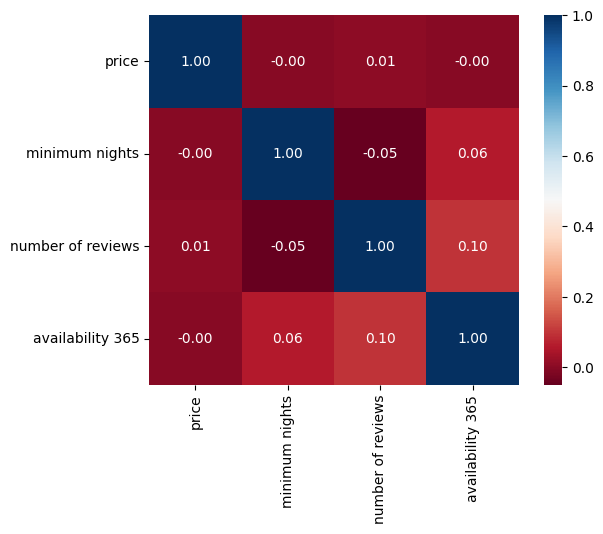

In [ ]:
sns.heatmap(corr, cmap='RdBu', fmt='.2f', square=True, linecolor='white', annot=True);

room type
Entire home/apt    53699
Private room       46550
Shared room         2226
Hotel room           116
Name: count, dtype: int64


room type
Entire home/apt    52.34
Private room       45.37
Shared room         2.17
Hotel room          0.11
Name: proportion, dtype: float64




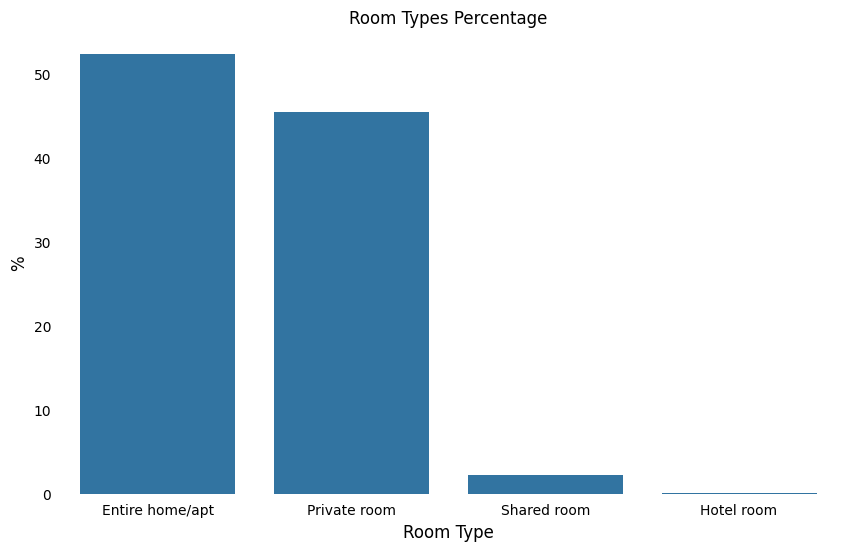

In [ ]:
# Calculating the number of rooms for each room type
room_type = df1['room type'].value_counts().sort_values(ascending=False)

# Calculating the percentage of rooms for each room type
room_type_pct = round(df1['room type'].value_counts(normalize=True) * 100, 2)

# Displaying the results
print(room_type)
print('\n')
print(room_type_pct)
print('\n')

# Plotting the percentage of rooms for each room type
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=room_type_pct.index, y=room_type_pct.values) 
ax.set_title('Room Types Percentage')
ax.set_ylabel('%', fontsize=12)
ax.set_xlabel('Room Type', fontsize=12)
ax.tick_params(bottom=False, top=False, left=False, right=False)
for key, spine in ax.spines.items():
    spine.set_visible(False)

plt.show()


In [ ]:
import plotly.graph_objects as go

# Define a custom dark color palette
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

# Calculating the average price per room type
type_price = round(df1.groupby('room type').price.mean(), 2).sort_values(ascending=False)

# Displaying the results
print("Average Price per Room Type:")
print(type_price)
print('\n')

# Create a bar plot
fig = go.Figure(data=[go.Bar(
    x=type_price.index,
    y=type_price.values,
    marker_color=colors,  # Use custom dark color palette
)])

# Update layout
fig.update_layout(
    title='Average Price per Room Type',
    xaxis=dict(title='Room Type'),
    yaxis=dict(title='Price ($)'),
)

# Add data labels
for i, val in enumerate(type_price.values):
    fig.add_annotation(
        x=type_price.index[i],
        y=val,
        text=f"${val:.2f}",
        showarrow=False,
        font=dict(color='white', size=10),
        yshift=5
    )

# Show the plot
fig.show()


Average Price per Room Type:
room type
Hotel room         668.47
Shared room        634.10
Entire home/apt    625.08
Private room       625.03
Name: price, dtype: float64




In [ ]:
import plotly.graph_objects as go

# Calculating the average minimum nights per room type
room_type_nights = round(df1.groupby('room type')['minimum nights'].mean(), 2).sort_values(ascending=False)

# Create a bar plot
fig = go.Figure(data=[go.Bar(
    x=room_type_nights.index,
    y=room_type_nights.values,
    marker_color='#1f77b4'  # Custom color
)])

# Update layout
fig.update_layout(
    title='Average Minimum Nights per Room Type',
    xaxis=dict(title='Room Type'),
    yaxis=dict(title='Minimum Nights'),
    showlegend=False,
)

# Show the plot
fig.show()


In [ ]:
import plotly.graph_objects as go

# Calculating the average price per region
price_region = round(df1.groupby('neighbourhood group').price.mean().sort_values(ascending=False), 2)
print(price_region)
# Create a bar plot
fig = go.Figure(data=[go.Bar(
    x=price_region.index,
    y=price_region.values,
    marker_color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'],  # Custom color palette
)])

# Update layout
fig.update_layout(
    title='Average Price per Region',
    xaxis=dict(title='Neighbourhood Group'),
    yaxis=dict(title='Price ($)'),
    showlegend=False,
)

# Show the plot
fig.show()

neighbourhood group
The Bronx        909.00
Queens           630.23
Bronx            627.76
Brooklyn         626.59
Staten Island    624.49
Manhattan        622.46
brookln          580.00
manhatan         460.00
Queens County    362.50
Name: price, dtype: float64


In [ ]:
import plotly.graph_objects as go

# Calculating the percentage of rooms per region
room_regions_pct = round(df1['neighbourhood group'].value_counts(normalize=True).sort_values(ascending=False) * 100, 2)

# Create a bar plot
fig = go.Figure(data=[go.Bar(
    x=room_regions_pct.index,
    y=room_regions_pct.values,
    marker_color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'],  # Custom color palette
)])

# Update layout
fig.update_layout(
    title='Rooms Percentage per Region',
    xaxis=dict(title='Neighbourhood Group'),
    yaxis=dict(title='%'),
    showlegend=False,
)

# Show the plot
fig.show()

In [ ]:
df1['price'].info()

<class 'pandas.core.series.Series'>
Index: 102591 entries, 0 to 102598
Series name: price
Non-Null Count   Dtype  
--------------   -----  
102591 non-null  float64
dtypes: float64(1)
memory usage: 5.6 MB


In [ ]:
from sklearn.preprocessing import StandardScaler
# Select the columns for clustering
X = df1[['price', 'minimum nights', 'number of reviews','service fee','lat','long']]

# Create an instance of the StandardScaler
scaler = StandardScaler()

# Fit the scaler to the data and transform X
X_scaled = scaler.fit_transform(X)

# Print the scaled data
print(X_scaled)


[[ 1.02844451  0.06205974 -0.37257132  1.02616897 -1.44305927 -0.4589171 ]
 [-1.45890519  0.71785992  0.35502405 -1.46483812  0.45699689 -0.68912236]
 [-0.01600088 -0.16747033 -0.55447016 -0.01552491  1.44882871  0.15637714]
 ...
 [ 1.09485433 -0.16747033 -0.55447016  1.10165403 -0.94964979 -0.62208013]
 [-0.23937937 -0.20026033 -0.45341525 -0.2419801   0.39021832  0.23977606]
 [ 1.22767397 -0.23305034 -0.55447016  1.22243013  0.7156967  -0.68205466]]


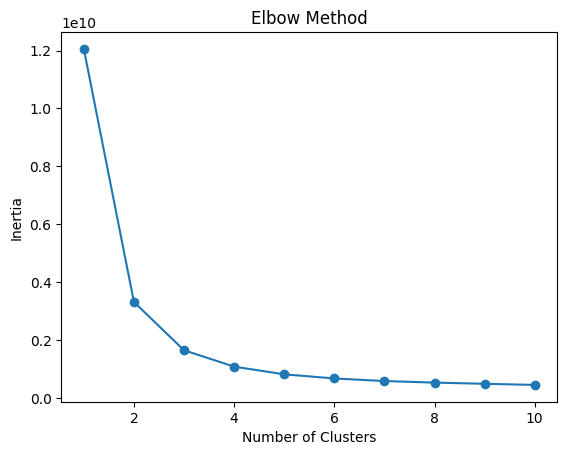

In [ ]:
# Elbow plot for Kmeans

# Function to find the optimum number of clusters
def find_optimum_clusters(df, max_k):
    # Initialize lists to store inertia values and number of clusters
    inertias = []
    num_clusters = []

    # Iterate over a range of cluster numbers from 1 to max_k
    for k in range(1, max_k+1):
        # Initialize and fit KMeans model
        kmeans = KMeans(n_clusters=k, random_state=0)
        kmeans.fit(df)

        # Append the inertia value and number of clusters to the lists
        inertias.append(kmeans.inertia_)
        num_clusters.append(k)

    # Plot the inertia values to visualize the elbow
    plt.plot(num_clusters, inertias, marker='o')
    plt.xlabel('Number of Clusters')
    plt.ylabel('Inertia')
    plt.title('Elbow Method')
    plt.show()

# Call the function to find the optimum number of clusters
find_optimum_clusters(X, 10)


In [ ]:

from sklearn.cluster import KMeans

# Initialize and fit KMeans model
kmeans = KMeans(n_clusters=3, random_state=0)  # Set a random state for reproducibility
kmeans.fit(X)

KMeans(n_clusters=3, random_state=0)

In [ ]:
# get the labels
cluster_labels = kmeans.labels_

# assign these clusters back into the dataframe
df1_k5 = df1.assign(cluster=cluster_labels)

# display the shape
df1_k5.shape

(102591, 27)

In [ ]:
# Most popular neighborhood in each cluster
popular_neighborhoods = df1_k5.groupby('cluster')['neighbourhood'].apply(lambda x: x.mode()[0])

# 2. Minimum price with corresponding house rules, number of reviews, and other details
min_price_info = df1_k5.loc[df1_k5.groupby('cluster')['price'].idxmin()]
min_price_info = min_price_info[['cluster', 'neighbourhood group', 'neighbourhood', 'host name', 'host id', 'price', 'service fee', 'availability 365', 'reviews per month', 'number of reviews']]

# 3. Maximum price with corresponding house rules, number of reviews, and other details
max_price_info = df1_k5.loc[df1_k5.groupby('cluster')['price'].idxmax()]
max_price_info = max_price_info[['cluster', 'neighbourhood group', 'neighbourhood', 'host name', 'host id', 'price', 'service fee', 'availability 365', 'reviews per month', 'number of reviews']]


# Minimum service fee in each cluster
min_service_fee_info = df1_k5.groupby('cluster').apply(lambda x: pd.Series({
    'Host ID': x.loc[x['service fee'].idxmin()]['host id'],
    'Host Name': x.loc[x['service fee'].idxmin()]['host name'],
    'Minimum Service Fee': x['service fee'].min(),
    'Neighbourhood Group': x.loc[x['service fee'].idxmin()]['neighbourhood group'],
    'Neighbourhood': x.loc[x['service fee'].idxmin()]['neighbourhood']
}))

# Maximum service fee in each cluster
max_service_fee_info = df1_k5.groupby('cluster').apply(lambda x: pd.Series({
    'Host ID': x.loc[x['service fee'].idxmax()]['host id'],
    'Host Name': x.loc[x['service fee'].idxmax()]['host name'],
    'Maximum Service Fee': x['service fee'].max(),
    'Neighbourhood Group': x.loc[x['service fee'].idxmax()]['neighbourhood group'],
    'Neighbourhood': x.loc[x['service fee'].idxmax()]['neighbourhood']
}))

# Average availability in days for each cluster
average_availability = df1_k5.groupby('cluster')['availability 365'].mean()

# Information on reviews per month in each cluster
reviews_per_month = df1_k5.groupby('cluster')['reviews per month'].mean()

# Display extracted information in tabular form with margins
print("Most Popular Neighborhood in Each Cluster:")
print(tabulate(pd.DataFrame(popular_neighborhoods).reset_index(), headers=['Cluster', 'Popular Neighborhood'], tablefmt='pretty'))
print("\n")

print("Minimum Price Information:")
print(tabulate(min_price_info, headers='keys', tablefmt='pretty'))
print("\n")

print("Maximum Price Information:")
print(tabulate(max_price_info, headers='keys', tablefmt='pretty'))
print("\n")

# Display minimum service fee information in tabular form
print("Minimum Service Fee in Each Cluster:")
print(tabulate(min_service_fee_info.reset_index(), headers='keys', tablefmt='pretty'))
print("\n")

# Display maximum service fee information in tabular form
print("Maximum Service Fee in Each Cluster:")
print(tabulate(max_service_fee_info.reset_index(), headers='keys', tablefmt='pretty'))
print("\n")

print("Average Availability in Days for Each Cluster:")
print(tabulate(pd.DataFrame(average_availability).reset_index(), headers=['Cluster', 'Average Availability'], tablefmt='pretty'))
print("\n")

print("Average Reviews Per Month in Each Cluster:")
print(tabulate(pd.DataFrame(reviews_per_month).reset_index(), headers=['Cluster', 'Average Reviews Per Month'], tablefmt='pretty'))
print("\n")


Most Popular Neighborhood in Each Cluster:
+---+---------+----------------------+
|   | Cluster | Popular Neighborhood |
+---+---------+----------------------+
| 0 |    0    |  Bedford-Stuyvesant  |
| 1 |    1    |  Bedford-Stuyvesant  |
| 2 |    2    |     Williamsburg     |
+---+---------+----------------------+


Minimum Price Information:
+-------+---------+---------------------+--------------------+----------------+-------------+-------+--------------------+------------------+-------------------+-------------------+
|       | cluster | neighbourhood group |   neighbourhood    |   host name    |   host id   | price |    service fee     | availability 365 | reviews per month | number of reviews |
+-------+---------+---------------------+--------------------+----------------+-------------+-------+--------------------+------------------+-------------------+-------------------+
| 67826 |    0    |        Bronx        |   Pelham Gardens   |     Barry      | 55116782511 | 429.0 | 125.028

In [ ]:
from IPython.display import IFrame

# Create a base map centered at the mean latitude and longitude
map_center = [df1_k5['lat'].mean(), df1_k5['long'].mean()]
mymap = folium.Map(location=map_center, zoom_start=10)

# Define colors for each cluster
colors = ['blue', 'red', 'green', 'orange', 'purple']  # Add more colors if needed

# Create a MarkerCluster layer for each cluster
for cluster, color in zip(df1_k5['cluster'].unique(), colors):
    cluster_data = df1_k5[df1_k5['cluster'] == cluster]
    marker_cluster = MarkerCluster().add_to(mymap)
    
    # Add markers for each data point in the cluster with specified color
    for idx, row in cluster_data.iterrows():
        folium.Marker(
            location=[row['lat'], row['long']],
            popup=f"Cluster: {row['cluster']}<br>Neighbourhood: {row['neighbourhood']}<br>Price: {row['price']}",
            icon=folium.Icon(color=color)
        ).add_to(marker_cluster)

# Save the map to an HTML file
map_file_path = 'cluster_map.html'
mymap.save(map_file_path)



In [ ]:
from sklearn.metrics import silhouette_score

# Calculate silhouette score for overall K-means clustering
silhouette_avg = silhouette_score(X, kmeans.labels_)
print("Silhouette Score for Overall K-Means Clustering:", silhouette_avg)

Silhouette Score for Overall K-Means Clustering: 0.5506091626269661


In [ ]:
#Clustering Based on Average Purchase Amount
#Here in this tab we have created new dataframe df1_clustered which contains the cluster information of each customer based on their average purchase amount.

# Calculate average purchase amount per customer ID
avg_price_per_neighbourhood = df1.groupby('neighbourhood group')['price'].mean().reset_index()
avg_price_per_neighbourhood_1=avg_price_per_neighbourhood.copy()
avg_price_per_neighbourhood_1.reset_index()
avg_price_per_neighbourhood_1.head()

,neighbourhood group,price
0,Bronx,627.759994
1,Brooklyn,626.586327
2,Manhattan,622.456231
3,Queens,630.226061
4,Queens County,362.500000


In [ ]:
print(avg_price_per_neighbourhood)

  neighbourhood group       price
0               Bronx  627.759994
1            Brooklyn  626.586327
2           Manhattan  622.456231
3              Queens  630.226061
4       Queens County  362.500000
5       Staten Island  624.493091
6           The Bronx  909.000000
7             brookln  580.000000
8            manhatan  460.000000


In [ ]:
# Include the 'id' column in avg_price_per_neighbourhood DataFrame
avg_price_per_neighbourhood['id'] = df1['id']  # Assuming 'id' is the column name in df1

# Now avg_price_per_neighbourhood DataFrame contains both 'neighbourhood group', 'price', and 'id'

# Merge avg_price_per_neighbourhood with df1
df1_clustered = df1.merge(avg_price_per_neighbourhood, on='neighbourhood group', how='left')
print(df1_clustered)


           id_x                                              NAME  \
0       1001254                Clean & quiet apt home by the park   
1       1002102                             Skylit Midtown Castle   
2       1002403               THE VILLAGE OF HARLEM....NEW YORK !   
3       1002755                                           No Name   
4       1003689  Entire Apt: Spacious Studio/Loft by central park   
...         ...                                               ...   
102586  6092437                        Spare room in Williamsburg   
102587  6092990                     Best Location near Columbia U   
102588  6093542                    Comfy, bright room in Brooklyn   
102589  6094094                  Big Studio-One Stop from Midtown   
102590  6094647                              585 sf Luxury Studio   

            host id      host_identity_verified    host name  \
0       80014485718                 unconfirmed     Madaline   
1       52335172823                    veri

In [ ]:
# Create another DataFrame with relevant customer information
customer_info = df1[['id', 'NAME', 'neighbourhood', 'service fee', 'reviews per month']]

# df1_clustered DataFrame now contains the cluster information along with the 'id' column
# Merge average purchase amount and cluster information to the customer information DataFrame
customer_info = customer_info.merge(avg_price_per_neighbourhood[['id',  'neighbourhood group', 'price']], on='id', how='left')

print(customer_info)

             id                                              NAME  \
0       1001254                Clean & quiet apt home by the park   
1       1002102                             Skylit Midtown Castle   
2       1002403               THE VILLAGE OF HARLEM....NEW YORK !   
3       1002755                                           No Name   
4       1003689  Entire Apt: Spacious Studio/Loft by central park   
...         ...                                               ...   
102586  6092437                        Spare room in Williamsburg   
102587  6092990                     Best Location near Columbia U   
102588  6093542                    Comfy, bright room in Brooklyn   
102589  6094094                  Big Studio-One Stop from Midtown   
102590  6094647                              585 sf Luxury Studio   

              neighbourhood  service fee  reviews per month  \
0                Kensington        193.0               0.21   
1                   Midtown         28.0     